In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
Spotify = pd.read_csv("spotify_songs.csv")
Tracks = Spotify.drop_duplicates(subset="track_id").copy()
Tracks["Duration_minutes"] = Tracks["duration_ms"] / 60000

sns.set_theme(style="whitegrid", font_scale=1.2)
plt.rcParams["figure.dpi"] = 120

print(f"Original rows: {len(Spotify)}")
print(f"Distinct track IDs: {len(Tracks)}")
print(f"Playlists: {Spotify['playlist_id'].nunique()}")

Original rows: 32833
Distinct track IDs: 28356
Playlists: 471


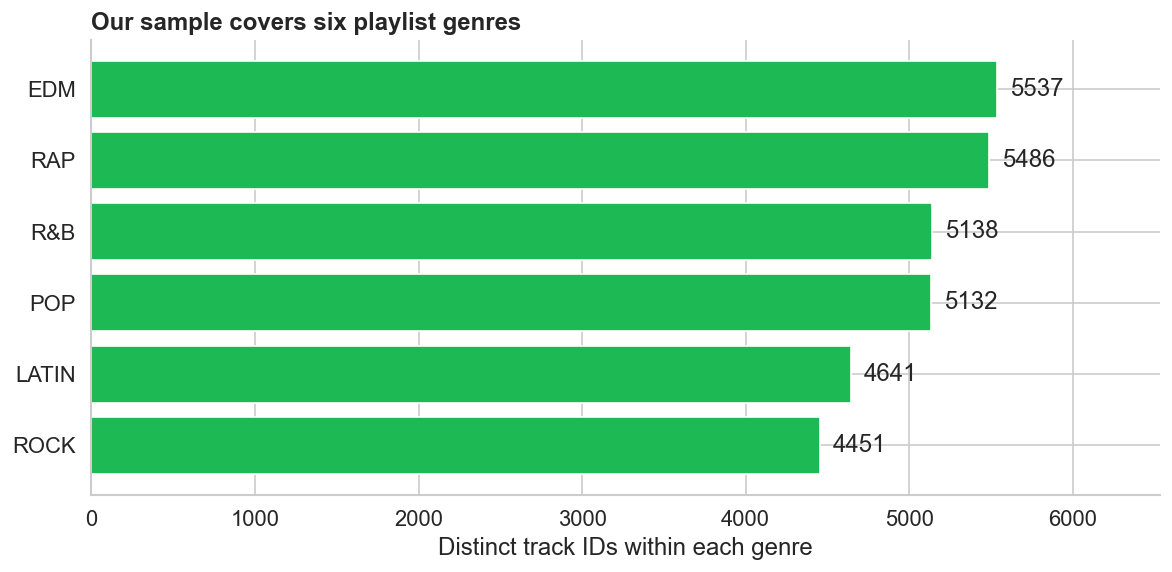

In [3]:
Genre_tracks = Spotify.drop_duplicates(subset=["track_id", "playlist_genre"])

Genre_counts = Genre_tracks["playlist_genre"].value_counts().sort_values()
Genre_counts.index = Genre_counts.index.str.upper()

plt.figure(figsize=(10, 5))
Bars = plt.barh(Genre_counts.index, Genre_counts.values, color="#1DB954")

plt.bar_label(Bars, padding=8, fmt="%.0f")
plt.xlim(0, Genre_counts.max() * 1.18)
plt.xlabel("Distinct track IDs within each genre")
plt.ylabel("")
plt.title("Our sample covers six playlist genres", loc="left", weight="bold")
sns.despine()
plt.tight_layout()
plt.savefig("01_genre_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

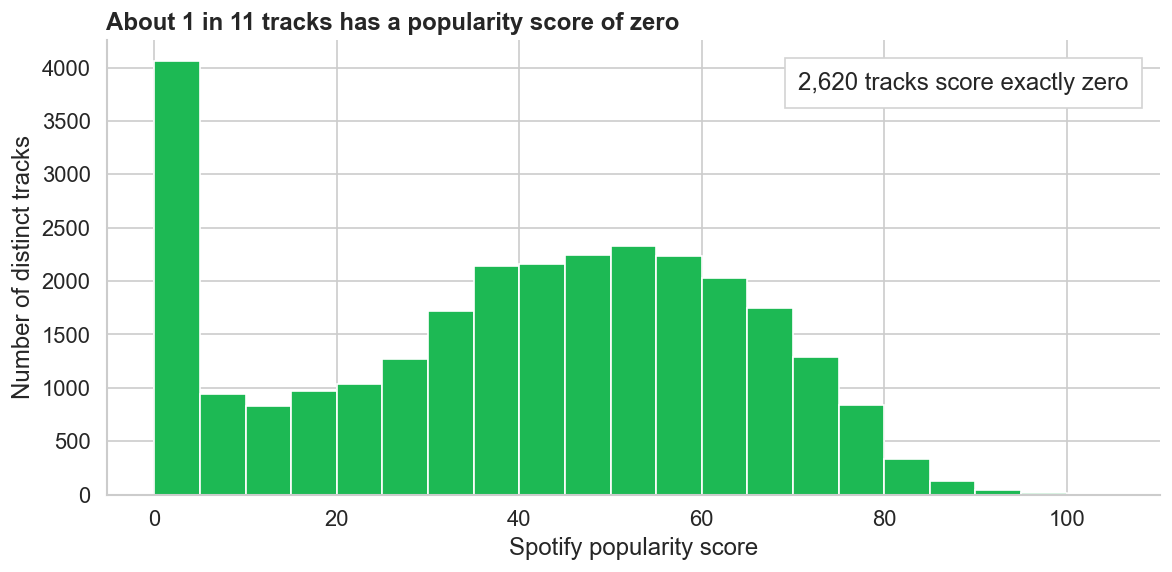

Percentage scoring exactly zero: 9.239667089857525


In [4]:
Zero_count = (Tracks["track_popularity"] == 0).sum()
Zero_percent = Zero_count / len(Tracks) * 100

plt.figure(figsize=(10, 5))
plt.hist(Tracks["track_popularity"],bins=range(0, 106, 5),color="#1DB954",edgecolor="white")

plt.xlabel("Spotify popularity score")
plt.ylabel("Number of distinct tracks")
plt.title("About 1 in 11 tracks has a popularity score of zero",loc="left",weight="bold")

plt.text(0.97, 0.93,f"{Zero_count:,} tracks score exactly zero",transform=plt.gca().transAxes, ha="right",va="top",
    bbox=dict(facecolor="white", edgecolor="lightgray", pad=8))

sns.despine()
plt.tight_layout()
plt.savefig("02_popularity_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Percentage scoring exactly zero: {Zero_percent}")

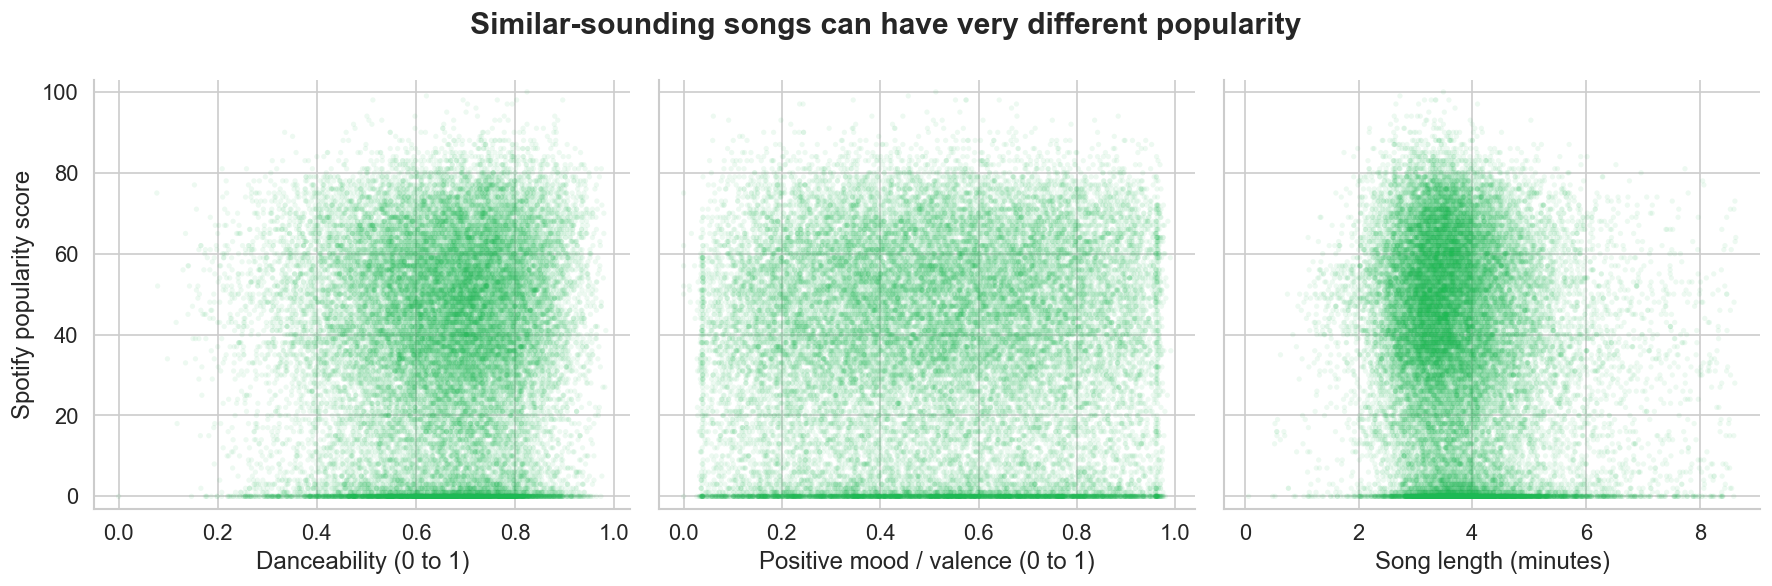

In [5]:
Features = ["danceability", "valence", "Duration_minutes"]
Labels = ["Danceability (0 to 1)","Positive mood / valence (0 to 1)", "Song length (minutes)"]

Figure, Axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for Position in range(len(Features)):
    Axes[Position].scatter(
        Tracks[Features[Position]],
        Tracks["track_popularity"],
        color="#1DB954",
        alpha=0.08,
        s=10,
        edgecolors="none")
    Axes[Position].set_xlabel(Labels[Position])
    Axes[Position].set_ylim(-3, 103)

Axes[0].set_ylabel("Spotify popularity score")
Figure.suptitle("Similar-sounding songs can have very different popularity",fontsize=18,weight="bold")

sns.despine()
plt.tight_layout()
plt.savefig("03_sound_and_popularity.png", dpi=300, bbox_inches="tight")
plt.show()

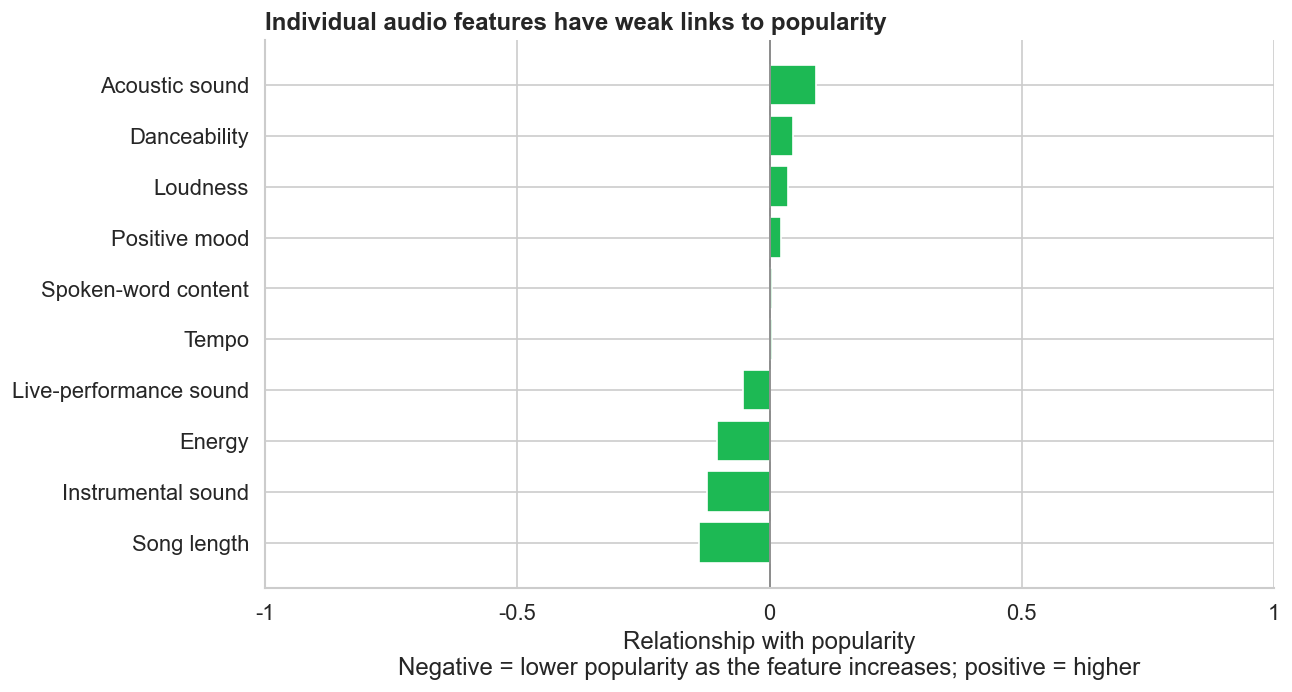

Song length              -0.139682
Instrumental sound       -0.124431
Energy                   -0.103622
Live-performance sound   -0.052773
Tempo                     0.004446
Spoken-word content       0.005206
Positive mood             0.022581
Loudness                  0.037285
Danceability              0.046597
Acoustic sound            0.091725
dtype: float64


In [6]:
Feature_names = {"danceability": "Danceability",
    "energy": "Energy",
    "loudness": "Loudness",
    "speechiness": "Spoken-word content",
    "acousticness": "Acoustic sound",
    "instrumentalness": "Instrumental sound",
    "liveness": "Live-performance sound",
    "valence": "Positive mood",
    "tempo": "Tempo",
    "Duration_minutes": "Song length"}

Relationships = Tracks[list(Feature_names)].corrwith(Tracks["track_popularity"])

Relationships = Relationships.rename(index=Feature_names).sort_values()

plt.figure(figsize=(11, 6))
plt.barh(Relationships.index,Relationships.values, color="#1DB954")

plt.axvline(0, color="gray", linewidth=1)
plt.xlim(-1, 1)
plt.xticks([-1, -0.5, 0, 0.5, 1],["-1", "-0.5", "0", "0.5", "1"])

plt.xlabel("Relationship with popularity\n"
    "Negative = lower popularity as the feature increases; positive = higher")

plt.title("Individual audio features have weak links to popularity",
    loc="left",
    weight="bold")

sns.despine()
plt.tight_layout()
plt.savefig("04_feature_relationships.png", dpi=300, bbox_inches="tight")
plt.show()

print(Relationships)